
# Hypothesis Testing in R — Student Shell

**Dataset files in this folder:** `iron_intake.csv`, `vmt.csv`  
**Kernel:** R (`ir`) | **Where to run:** Jupyter Notebook

## Instructions
- Complete the code cells where indicated by **YOUR CODE HERE**.
- Write short interpretations below your outputs.
- Keep your final exported PDF to **≤ 4 pages**.


In [1]:

# Load packages
# If not installed: 
# install.packages('tidyverse')
library(readr)
library(dplyr)
library(ggplot2)

# Set working directory if needed (uncomment and edit):
# setwd('path/to/this/folder')

iron <- read_csv('iron_intake.csv')
vmt  <- read_csv('vmt.csv')

head(iron)
head(vmt)


Warning message:
"package 'readr' was built under R version 4.6.2"

Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union


Warning message:
"package 'ggplot2' was built under R version 4.6.2"
Rows: 45 Columns: 1
── Column specification ────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: ","
dbl (1): iron_mg

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 29 Columns: 2
── Column specification ────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: ","
chr (1): region
dbl (1): vmt_k

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this me

iron_mg
<dbl>
15.0
18.1
14.4
14.6
10.9
18.1


region,vmt_k
<chr>,<dbl>
Midwest,16.2
Midwest,12.9
Midwest,17.3
Midwest,14.6
Midwest,18.6
Midwest,10.8



## Task 1 — One-sample t-test (Iron Intake vs. RDA)

Goal: Test whether the mean daily iron intake for adult females under 51 differs from the RDA of 18 mg/day.

1. Visualize the distribution (histogram + Q-Q plot).
2. Run a **one-sample t-test** (two-sided) with `mu = 18`.
3. Report: sample mean, t statistic, df, p-value, and a plain-language interpretation at α = 0.05.


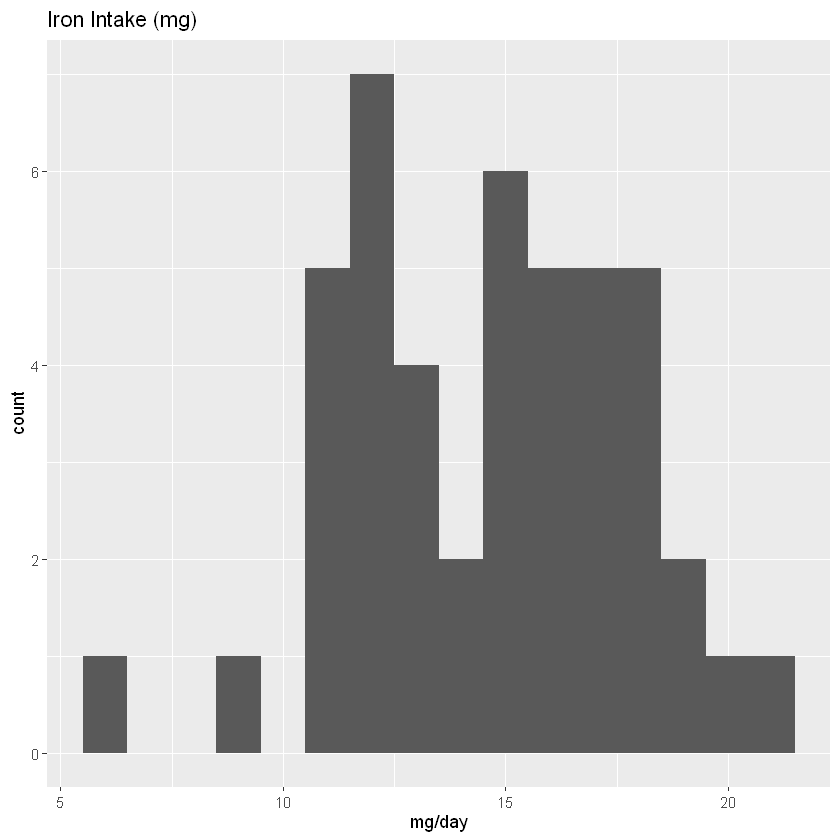

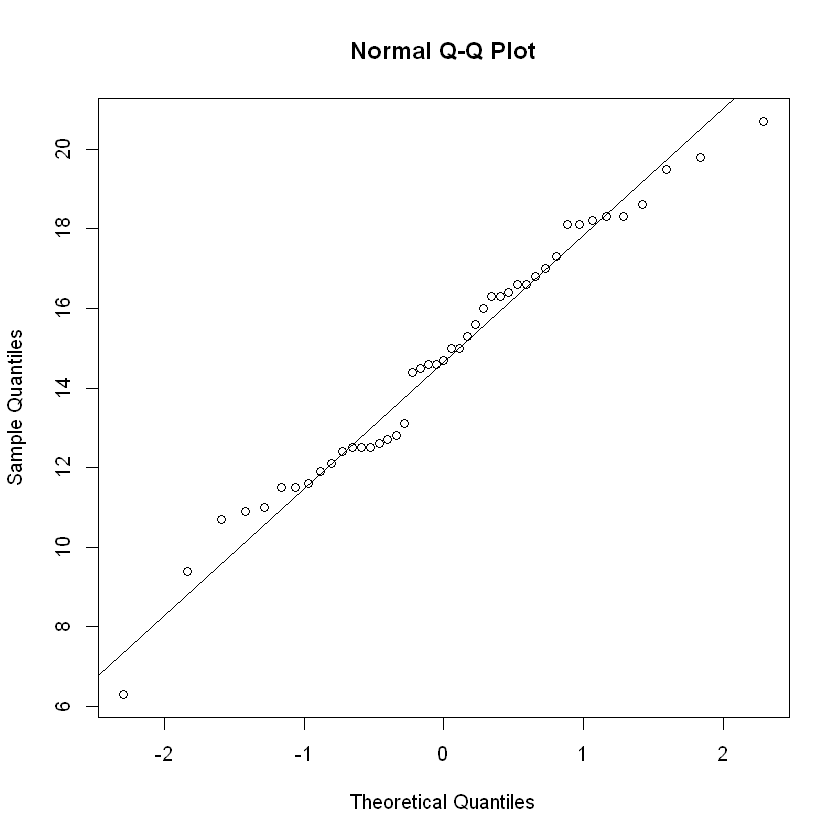

In [2]:
# 1) Visualize
ggplot(iron, aes(x = iron_mg)) +
  geom_histogram(binwidth = 1) +
  labs(title = 'Iron Intake (mg)', x = 'mg/day', y = 'count')

qqnorm(iron$iron_mg); qqline(iron$iron_mg)

In [3]:
# 2) One-sample t-test
# YOUR CODE HERE: run t.test on iron$iron_mg with mu = 18, two-sided
iron_test <- t.test(iron$iron_mg, mu = 18)
print(iron_test)


	One Sample t-test

data:  iron$iron_mg
t = -7.2234, df = 44, p-value = 5.386e-09
alternative hypothesis: true mean is not equal to 18
95 percent confidence interval:
 13.7537 15.6063
sample estimates:
mean of x 
    14.68 



In [4]:
# 3) Extract and print key stats
# YOUR CODE HERE: compute sample mean and print
iron_mean <- mean(iron$iron_mg)
cat('sample mean:', iron_mean, 'mg/day\n')

cat('t statistic:', unname(iron_test$statistic), '\n')
cat('df:', unname(iron_test$parameter), '\n')
cat('p-value:', iron_test$p.value, '\n')


# 4) Interpretation (write in Markdown below)


sample mean: 14.68 mg/day
t statistic: -7.223394 
df: 44 
p-value: 5.385818e-09 



**Your interpretation (2–4 sentences):**  
*(Explain whether you reject or fail to reject H0 and what that means in context.)*


We reject $H_0$ because $p \lt 0.05$. There is statistically significant evidence that the population mean iron intake is different from the reference value of 18 mg/day. The sample mean iron intake of 14.68 mg/day suggests that the population mean is lower than this RDA.


## Task 2 — Two-sample independent t-test (VMT by Region)

Goal: Compare mean household **Vehicle Miles Traveled (VMT)** between **Midwest** and **South**.

1. Visualize by group (boxplot + summary).
2. Run a two-sample t-test (assume equal variances by default for this assignment).
3. Report: group means, t statistic, df, p-value, and interpret at α = 0.05.


region,n,mean,sd
<chr>,<int>,<dbl>,<dbl>
Midwest,15,16.22667,4.055062
South,14,17.68571,4.422470


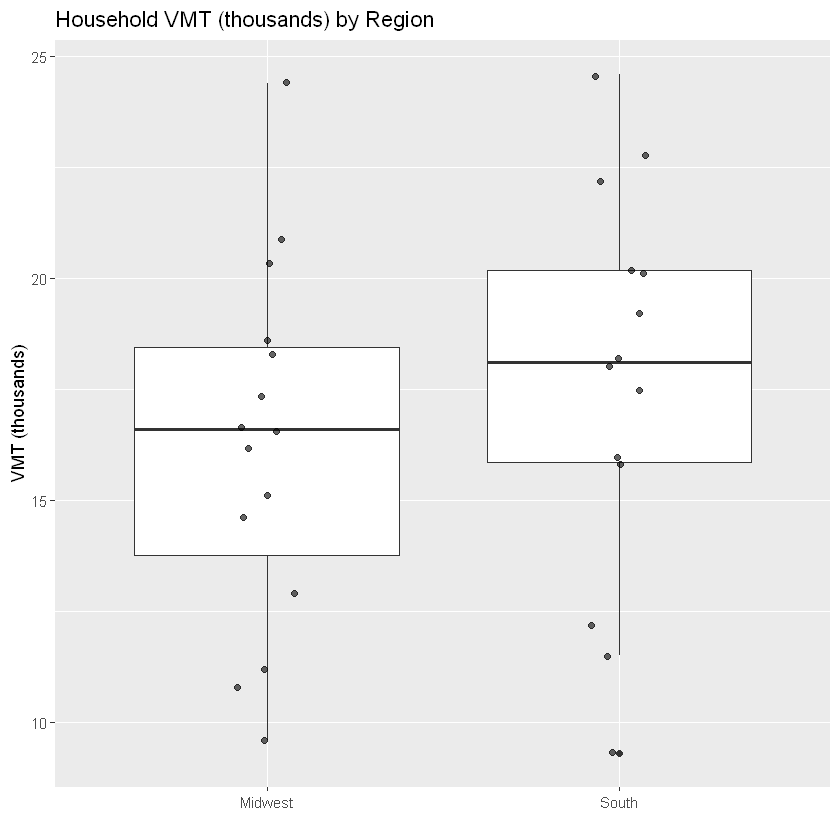

In [5]:

# 1) Visualize
vmt %>%
  ggplot(aes(x = region, y = vmt_k)) +
  geom_boxplot() +
  geom_jitter(width = 0.1, alpha = 0.6) +
  labs(title = 'Household VMT (thousands) by Region', x = '', y = 'VMT (thousands)')

vmt %>% group_by(region) %>% summarise(n = n(), mean = mean(vmt_k), sd = sd(vmt_k))

In [6]:
# 2) Two-sample t-test
vmt_test <- t.test(vmt_k ~ region, data = vmt, var.equal = TRUE)
print(vmt_test)

# 3) Interpretation (write in Markdown below)



	Two Sample t-test

data:  vmt_k by region
t = -0.92689, df = 27, p-value = 0.3622
alternative hypothesis: true difference in means between group Midwest and group South is not equal to 0
95 percent confidence interval:
 -4.688886  1.770791
sample estimates:
mean in group Midwest   mean in group South 
             16.22667              17.68571 



In [7]:
midwest_mean <- mean(vmt$vmt_k[vmt$region == 'Midwest'])
cat('midwest mean:', midwest_mean, 'thousand miles\n')
south_mean <- mean(vmt$vmt_k[vmt$region == 'South'])
cat('south mean:', south_mean, 'thousand miles\n')

cat('t statistic:', unname(vmt_test$statistic), '\n')
cat('df:', unname(vmt_test$parameter), '\n')
cat('p-value:', vmt_test$p.value)

midwest mean: 16.22667 thousand miles
south mean: 17.68571 thousand miles
t statistic: -0.9268941 
df: 27 
p-value: 0.3621934


**Your interpretation (2–4 sentences):**  
*(Explain whether you reject or fail to reject H0 about equal means and what that implies.)*


We fail to reject $H_0$ because $p \gt 0.05$. The South has a higher sample mean VMT than the Midwest, but there is not statistically significant evidence that the population mean VMT is different for the Midwest and the South.